# Use existing modules

Before you start implementing a certain functionality, you should check if someone else has already done this work. Such "foreign code" is available in the form of modules and packages, which you can easily import into your program if needed. We have to distinguish between packages/modules

 * from the standard library
 * from a third party

## The standard library

Python comes with *batteries included*. What is meant by this is that when Python is installed, numerous modules and packages for a wide variety of purposes are installed along with it and are thus immediately usable. This "standard library" is documented in detail: https://docs.python.org/3/library/index.html.
This very extensive documentation, which covers more than 2000 pages as PDF, describes all modules of the installed Standard Library. The description is organized according to possible applications. In the table of contents you find (here only excerpts taken) these main points:

* Built-in Constants
* Built-in Types
* Built-in Exceptions
* Text Processing Services
* Binary Data Services
* Data Types
* Numeric and Mathematical Modules
* Functional Programming Modules
* File and Directory Access
* Data Persistence
* Data Compression and Archiving
* File Formats
* Cryptographic Services
* Generic Operating System Services
* Concurrent Execution
* Structured Markup Processing Tools
* Internet Protocols and Support
* Multimedia Services
* Internationalization
* Graphical User Interfaces with Tk
* Development Tools
* Debugging and Profiling
* ...

Under `Numeric and Mathematical Modules` we find e.g. a module `random - Generate pseudo-random numbers`:
https://docs.python.org/3/library/random.html, which we can look at as an example. At first it is described what the module can be used for. This is followed by an enumeration of constants (if any) and all functions of the module, often with a small example. E.g. the function `choice()` is described like this:


#### random.choice(seq)

Return a random element from the non-empty sequence seq. If seq is empty, raises IndexError.



### Using a module from the standard library

To use the `choice()` function described above, we must first import the module into our program. After that the function is available to us:

In [ ]:
import random

students = ['Otto', 'Anna', 'Santa', 'Claus', 'Kat']
print(random.choice(students))

So `choice()` randomly chooses an element from our list. Try it out by running the code snippet multiple times!

To check if `choice()` works reliably, we can run it in a loop and then count how many times each element was selected. For this we do not use the self-written counter from the notebook to the dictionaries, but a counter object provided by the standard library. If we call `choice()` 100 000 times, at the end each of the five names should occur about 20 000 times.

In [ ]:
from collections import Counter
import random

students = ['Otto', 'Anna', 'Santa', 'Claus', 'Kat']

random_students = []
for _ in range(100000):
    random_students.append(random.choice(students))

counter = Counter(random_students)
print(counter)

<div class="alert alert-block alert-info">
<b>Exercise StdLib-1</b>
    
Use the <tt>random</tt> library to generate a random number from a range of numbers 1-100.</div>

With the Standard Library you have a really powerful tool at hand. You should therefore also invest time to read at least the table of contents and some module descriptions to get an idea of what is covered by the Standard Library.

## External libraries

Although the Standard Library provides many modules, this covers only a small fraction of what is available in terms of useful modules. Many programmers make the libraries they have written available for reuse. These, as we will see in a moment, can be easily installed and then imported like a module of the Standard Library. The central resource for such third-party modules is the **Py**thon **P**ackage **I**ndex: https://pypi.org/

On this page you can search for existing modules by simply entering one or more search terms. PyPi currently contains more than 300 000 projects. So the chance that you will find what you are looking for is relatively high. Many of the projects also provide a link to documentation, which you should definitely look at before using a library. If you plan to share your code, you should also take a look at how the libraries you use are licensed, because the license determines how you are allowed to use other people's code.

### Installing a library from pypi

The easiest way to use a module from pypi is to use `pip`. This is a package manager that you can use to install, update or uninstall things from PyPi (possibly from elsewhere). If you have a Conda-based Python installation, `pip` also works, but here it is recommended to use `conda` as package manager instead of pip. Conda does not use pypi, but its own (smaller) package collection. If a package is not available with Conda, there is nothing against working with `pip` here as well.

A big advantage of a package manager, besides the very easy possibility to reinstall modules and packages, is that it recognizes and takes dependencies into account. So if we install module A with pip (or conda), the package manager recognizes that A itself needs certain libraries again (so e.g. module B and package C) and installs them as well.

### Crash course pip

Basically it is recommended to use a *virtual environment* for such experiments. The advantage is that `pip` then installs things in the virtual environment and not in the system-wide Python environment. So we first create a venv named `piptest` and activate it. **Important**: This will not work in a notebook. You need to type the commands in a prompt/shell like cmd, powershell or a terminal.

First we create the `venv` named `piptest` (in a directory with the same name).
```
python -m venv piptest
```
Then we have to activate the `venv`:

On Windows:

```
piptest\Scripts\activate
```

or for Powershell
```
piptest\Scripts\activate.ps1
```

On OSX or Linux, type this:

```
source piptest\Scripts\activate
```

You should now see that you are in a venv, because (piptest) is displayed in the prompt.

If we now install something with `pip`, it will only be installed in the venv `piptest`, and not in normal Python.

Now let's install e.g. the `requests` library, with which we can comfortably make http requests on the WWW:

```
pip install requests
```

Before the installation we could have displayed details about the package:

```
pip show requests
```

We could even install a specific (older) version. 

```
pip install requests==1.2.3
```

The package can be updated (i.e. brought to the current version):

```
pip install --upgrade requests
```

If we don't need it anymore, we can remove a package:

```
pip uninstall requests
```

To leave the virtual environment and get back to the 'normal' python, just type:
```
deactivate
```

### Using the venv in JupyterLab

The commands above are typed in a terminal. The code in a notebook, however, is not executed by the terminal but by a *kernel*: a separate Python process that JupyterLab starts in the background. Activating a venv in a terminal therefore does **not** change which Python your notebook uses, and there is no command you can run in a notebook cell to "activate" a venv. Instead, we make the venv available as a kernel and select this kernel in JupyterLab.

**Step 1: Install `ipykernel` in the venv.** Activate the venv in a terminal (see above) and type:

```
pip install ipykernel
```

**Step 2: Register the venv as a kernel** (the venv must still be active):

```
python -m ipykernel install --user --name piptest --display-name "Python (piptest)"
```

`--name` is the internal name of the kernel, `--display-name` is the name you will see in JupyterLab.

**Step 3: Start JupyterLab.** Jupyter itself does not have to be installed in the venv. Start it as usual, for example from your normal Python or Conda environment (you can type `deactivate` first):

```
jupyter lab
```

**Step 4: Select the kernel.** There are two ways to do this:

* In the Launcher, click the `Python (piptest)` button under *Notebook* to create a new notebook that uses the venv.

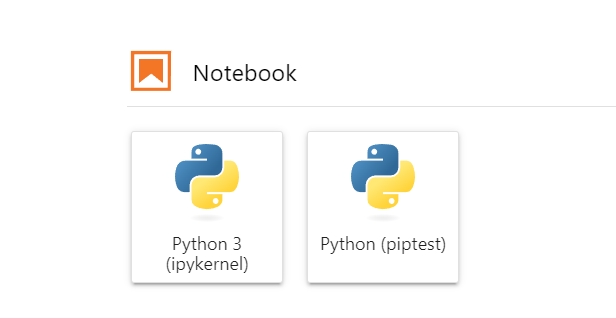

* In an already open notebook, choose *Kernel → Change Kernel...* from the menu (or click the kernel name in the top right corner) and select `Python (piptest)`.

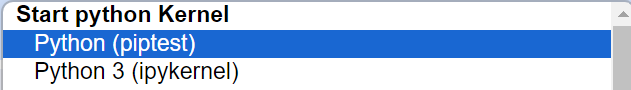

**Step 5: Check that it worked.** Run the following cell. The path it prints should contain `piptest`.

In [ ]:
import sys
print(sys.executable)

On Windows the path ends with something like `piptest\Scripts\python.exe`, on OSX or Linux with `piptest/bin/python`. If you see the path of your system-wide Python instead, the notebook is still using the default kernel (`Python 3 (ipykernel)`).

#### Installing packages from inside a notebook

Once the notebook runs in the venv, you can also install packages directly from a cell. Use the magic command `%pip` (not `!pip`), because it makes sure the package is installed in the environment of the running kernel:

In [ ]:
%pip install requests

If you import a module and then install a different version of it, restart the kernel (*Kernel → Restart Kernel...*) so that the new version is loaded.

#### Managing kernels

These commands are also typed in a terminal, not in a notebook:

```
jupyter kernelspec list
```
shows all registered kernels, and

```
jupyter kernelspec uninstall piptest
```
removes the kernel again (this does not delete the venv itself).

If the new kernel does not show up in JupyterLab, reload the browser tab or restart JupyterLab.

## Digression - important NLP (Natural Language Processing) modules:


* <b>NLTK</b> - Natural Language Toolkit (https://www.nltk.org/, https://pypi.org/project/nltk/)
    * a toolkit for computational linguistics in Python
    * most popular for NLP (Natural Language Processing)
    * provides corpora, lexical resources and libraries for all sorts of NLP tasks such as classification, tokenization, parsing, stemming, tagging, etc.

      
* <b> Spacy</b> (https://spacy.io/, https://spacy.io/usage)
    * a library for advanced NLP in Python 
    * an industry standard
    * offers models for a large variety of languages for taks such as tokenization, summarization, sentiment analysis, topic modelling, etc.
    
* <b> Textblob</b>(https://textblob.readthedocs.io/en/dev/)
    * library for processing textual data
    * offers  part-of-speech tagging, noun phrase extraction, sentiment analysis, classification, translation, and more
    
<b>These libraries acount for a variety of common NLP(Natural Language Processing) tasks.</b>
Such as:
  * <b> tokenization</b> - separating the text into smaller units (usually sentences or words words)
  * <b> automatic summarization (extractive, abstractive) </b> - a process of shortening a set of data computationally, to create a subset (a summary) that represents the most important or relevant information within the original content
  * <b> POS (part-of-speech) tagging</b> - categorizing words in a text (corpus) in correspondence with a particular part of speech, depending on the definition of the word and its context (e.g. noun phrase, noun, verb, preposition...)
  *  <b>sentiment analysis</b> - automatic detection of sentiments, emotions, and opinions in textual data
  *  <b>Named Entity Recognition </b>- identification of key information in the text and classification into a set of predefined categories (e.g. person, place, organization)
  *  <b>Topic Modelling </b> - identifying most relevant terms/ concepts of a text


This notebook is a part of the course Introduction to Programming at the University of Graz. The notebook was adapted by Klara Venglarova from the original notebook of Lucija Brozić.